# Notebook de Regresión Ampliado: Predicción de Ingresos con la EPH
Este cuaderno contiene el flujo completo de ciencia de datos para predecir ingresos laborales a partir de variables demográficas y socioeconómicas de la Encuesta Permanente de Hogares (EPH) del INDEC, Argentina.

**Actualización:** Se han incluido nombres de variables claros, legibles y descriptivos basados en el diccionario oficial.

## 1 - Ingesta y Renombrado de Datos

* Intentamos obtener el archivo zip con el dataset desde: https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_usu_1_Trim_2026_txt.zip
* Si pudimos obtenerlo lo descomprimos en memoria e intentamos leer el archivo usu_individual_T126.txt
* En caso de error la ingesta la realizamos desde https://github.com/aafustet/IPH/raw/main/data/usu_individual_T126.parquet

* Renombramos las columnas a algo mas descriptivo


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import requests
import io
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Intentar cargar el archivo localmente si existe, o generar datos sintéticos
try:
    archivo = "usu_individual_T126.txt"
    url     = "https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_usu_1_Trim_2026_txt.zip"

    # Descargar el archivo ZIP en memoria
    response = requests.get(url)
    response.raise_for_status()  # Verifica que la descarga fue exitosa

    # Abrir el archivo ZIP desde la memoria
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        # Obtener el nombre del primer archivo CSV dentro del ZIP
        #csv_filename = [f for f in z.namelist() if f.endswith(".csv")][0]
       
        with z.open(archivo) as f:
            df = pd.read_csv(f, sep=";", low_memory=False)

        
        print("Dataset original cargado desde INDEC.")
        print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

except:
    try:
        url = 'https://github.com/aafustet/IPH/raw/main/data/usu_individual_T126.parquet'
        df = pd.read_parquet(url, engine="pyarrow")
        print("Dataset cargado desde github.")
        print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
    except:
        print("Archivo no encontrado.")

diccionario_nombres = {
    'P21': 'ingreso_ocupacion_principal',
    'CH06': 'edad',
    'PP3E_TOT': 'horas_trabajadas_semanales',
    'CH04': 'sexo',
    'CH07': 'estado_civil',
    'NIVEL_ED': 'nivel_educativo',
    'REGION': 'region_geografica',
    'CAT_OCUP': 'categoria_ocupacional',
    'PP07H': 'tiene_descuento_jubilatorio',
    'PP04A': 'sector_publico_privado',
    'PP04C99': 'tamano_empresa',
    'PP07C': 'duracion_empleo',
    'PP07K': 'tipo_comprobante_cobro'
}

df_renombrado = df.rename(columns=diccionario_nombres)
print(f'Filas totales: {df_renombrado.shape[0]}, Columnas totales: {df_renombrado.shape[1]}')

Dataset original cargado desde INDEC.
Filas: 43739, Columnas: 234
Filas totales: 43739, Columnas totales: 234


## 2 Calidad de Datos y Filtrado

Para predecir ingresos laborales, no sirve analizar a personas que no trabajan (desocupados, niños, jubilados) o que no respondieron cuánto ganan.

Se aplica un filtro estricto: **solo con personas ocupadas que tengan un ingreso mayor a cero pesos**. Al hacer esto, el dataset se reduce de 43739 filas a 15448 registros útiles.



In [3]:
df_filtrado = df_renombrado[(df_renombrado['ESTADO'] == 1) & (df_renombrado['ingreso_ocupacion_principal'] > 0)].copy()
print(f'Registros en el universo de interés (Ocupados con ingresos positivos): {df_filtrado.shape[0]}')

Registros en el universo de interés (Ocupados con ingresos positivos): 15448


## 3 Exploración de Datos (EDA)

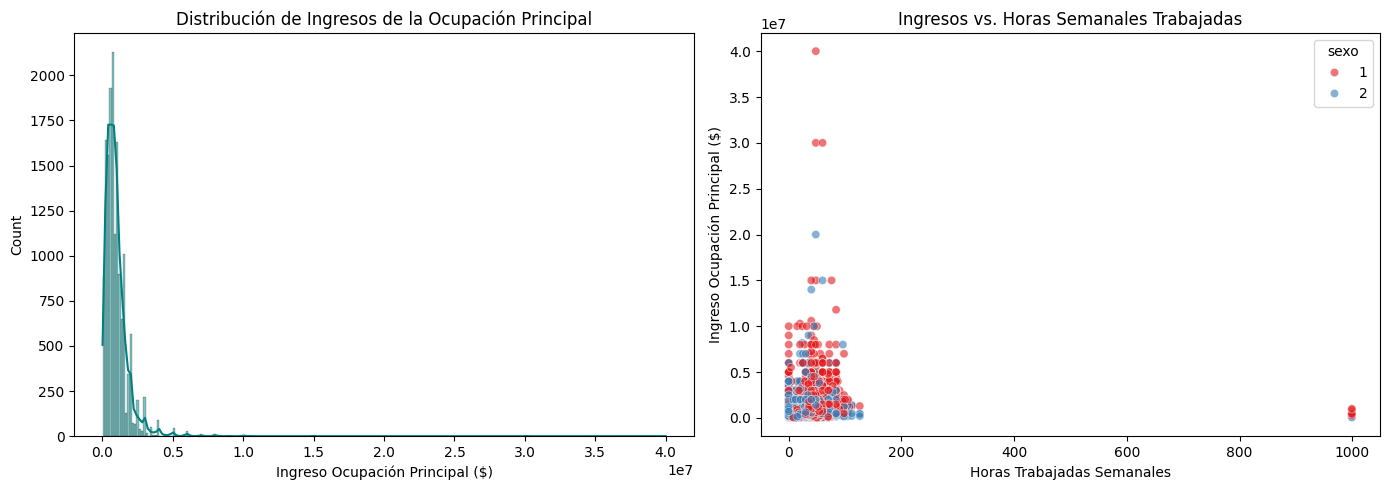

In [4]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_filtrado['ingreso_ocupacion_principal'], kde=True, color='teal')
plt.title('Distribución de Ingresos de la Ocupación Principal')
plt.xlabel('Ingreso Ocupación Principal ($)')
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_filtrado, x='horas_trabajadas_semanales', y='ingreso_ocupacion_principal', alpha=0.6, hue='sexo', palette='Set1')
plt.title('Ingresos vs. Horas Semanales Trabajadas')
plt.xlabel('Horas Trabajadas Semanales')
plt.ylabel('Ingreso Ocupación Principal ($)')
plt.tight_layout()
plt.show()

## 4 Preparación de Datos e Ingeniería de Atributos

In [5]:
## 4/6 Preparación de Datos e Ingeniería de Atributos

# 1. Filtro de Outliers (Valores atípicos severos basados en el rango intercuartílico)
Q1 = df_filtrado['ingreso_ocupacion_principal'].quantile(0.25)
Q3 = df_filtrado['ingreso_ocupacion_principal'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

# Creamos el dataset preparado excluyendo los outliers
df_preparado = df_filtrado[df_filtrado['ingreso_ocupacion_principal'] <= limite_superior].copy()
print(f'Registros restantes tras excluir valores atípicos severos (> {limite_superior:.2f}): {df_preparado.shape[0]}')

# 2. Definición de las variables que usará el modelo
var_numericas_actualizadas = ['edad', 'horas_trabajadas_semanales']
var_categoricas_actualizadas = [
    'sexo', 'estado_civil', 'nivel_educativo',
    'region_geografica', 'categoria_ocupacional', 'tiene_descuento_jubilatorio',
    'sector_publico_privado', 'tamano_empresa', 'duracion_empleo', 'tipo_comprobante_cobro'
]

# 3. Separación de características (X) y objetivo (y)
X = df_preparado[var_numericas_actualizadas + var_categoricas_actualizadas]

# >>> TRUCO ECONÓMICO: Aplicamos transformación logarítmica a la variable de ingresos <<<
y = np.log1p(df_preparado['ingreso_ocupacion_principal'])

# 4. División del dataset en conjuntos de Entrenamiento (80%) y Testeo (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Creación del Preprocesador (Pipeline de transformación automatizada)
# Para las numéricas: Estandarización (StandardScaler)
transformer_numerico = Pipeline(steps=[('scaler', StandardScaler())])

# Para las categóricas: Conversión a variables binarias 1 y 0 (OneHotEncoder)
transformer_categorico = Pipeline(steps=[('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))])

# Combinamos ambos procesadores en una sola tubería por columnas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', transformer_numerico, var_numericas_actualizadas),
        ('cat', transformer_categorico, var_categoricas_actualizadas)
    ])


Registros restantes tras excluir valores atípicos severos (> 2325000.00): 14613


## 5 Modelado y Optimización

In [6]:
modelos = {
    'Regresión Lineal': Pipeline(steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())]),
    'Ridge': Pipeline(steps=[('preprocessor', preprocessor), ('regressor', Ridge())]),
    'Random Forest': Pipeline(steps=[('preprocessor', preprocessor), ('regressor', RandomForestRegressor(random_state=42))])
}

params_ridge = {'regressor__alpha': [0.1, 1.0, 10.0, 100.0]}
params_rf = {'regressor__n_estimators': [50, 100], 'regressor__max_depth': [5, 10, None]}

grid_ridge = GridSearchCV(modelos['Ridge'], params_ridge, cv=5, scoring='r2')
grid_ridge.fit(X_train, y_train)

grid_rf = GridSearchCV(modelos['Random Forest'], params_rf, cv=5, scoring='r2', n_jobs=-1)
grid_rf.fit(X_train, y_train)

modelos['Regresión Lineal'].fit(X_train, y_train)

modelos_finales = {
    'Regresión Lineal': modelos['Regresión Lineal'],
    'Ridge Optimizada': grid_ridge.best_estimator_,
    'Random Forest Optimizado': grid_rf.best_estimator_
}

## 6 Evaluación e Importancia de Características

=== CUADRO COMPARATIVO DE RENDIMIENTO (CON LOG EN INGRESO) ===
                  Modelo R2 Score         MAE          RMSE
        Regresión Lineal  -4.8343 $328,212.06 $1,229,641.16
        Ridge Optimizada  -4.8854 $328,421.71 $1,235,011.65
Random Forest Optimizado   0.4526 $271,249.60   $376,657.40




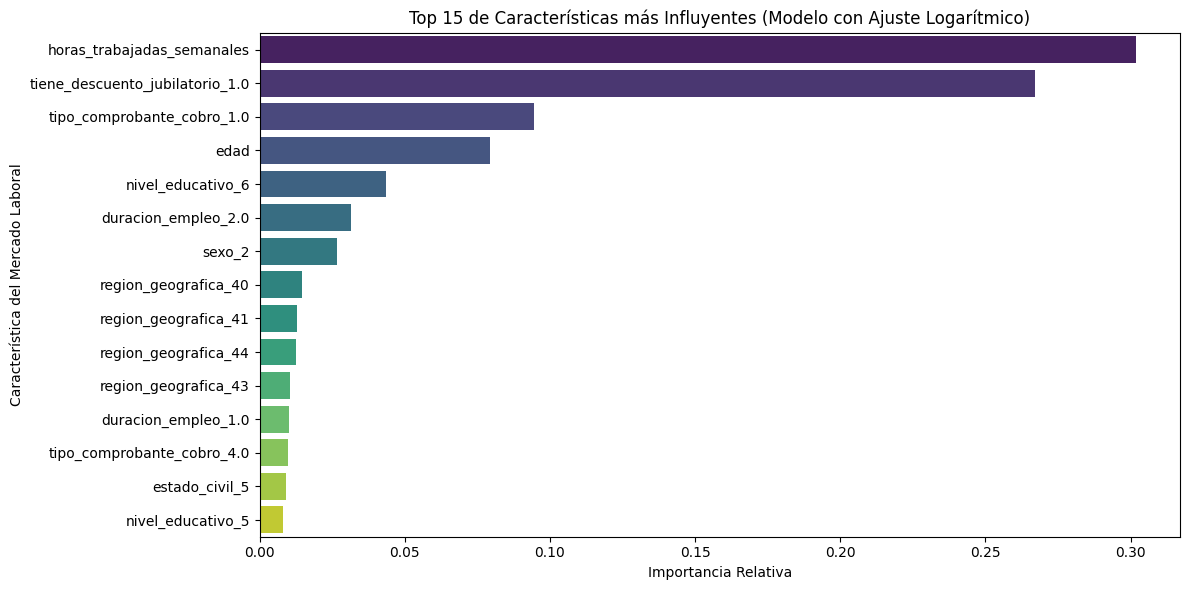

In [7]:
## 6/6 Evaluación e Importancia de Características

# 1. Creación del cuadro comparativo aplicando la transformación inversa
resultados = []

for nombre, modelo in modelos_finales.items():
    # El modelo predice en escala logarítmica sobre el conjunto de testeo
    predicciones_log = modelo.predict(X_test)
    
    # TRUCO INVERSO: Volvemos las predicciones y los valores reales a PESOS ARGENTINOS reales
    predicciones_pesos = np.expm1(predicciones_log)
    y_test_pesos = np.expm1(y_test)
    
    # Calculamos las métricas directamente sobre la escala de dinero real
    r2 = r2_score(y_test_pesos, predicciones_pesos)
    mae = mean_absolute_error(y_test_pesos, predicciones_pesos)
    rmse = np.sqrt(mean_squared_error(y_test_pesos, predicciones_pesos))
    
    resultados.append({
        'Modelo': nombre, 
        'R2 Score': f'{r2:.4f}', 
        'MAE': f'${mae:,.2f}', 
        'RMSE': f'${rmse:,.2f}'
    })

# Convertimos a DataFrame e imprimimos los resultados
df_resultados = pd.DataFrame(resultados)
print('=== CUADRO COMPARATIVO DE RENDIMIENTO (CON LOG EN INGRESO) ===')
print(df_resultados.to_string(index=False))
print("\n" + "="*50 + "\n")

# 2. Análisis e Importancia de Características (Feature Importance)
# Extraemos los nombres de las columnas categóricas después de aplicar OneHotEncoder
encoded_cat_features = modelos_finales['Random Forest Optimizado'].named_steps['preprocessor'] \
                                     .named_transformers_['cat'] \
                                     .named_steps['onehot'] \
                                     .get_feature_names_out(var_categoricas_actualizadas)

# Consolidamos la lista completa de todas las características (numéricas + categóricas codificadas)
todas_las_features = list(var_numericas_actualizadas) + list(encoded_cat_features)

# Obtenemos el vector de importancia del modelo ganador
importancias = modelos_finales['Random Forest Optimizado'].named_steps['regressor'].feature_importances_

# Creamos un DataFrame ordenado de mayor a menor impacto
df_importancia = pd.DataFrame({
    'Característica': todas_las_features, 
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

# Graficamos el Top 15 de las características más influyentes en los ingresos
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_importancia.head(15), 
    x='Importancia', 
    y='Característica', 
    hue='Característica', 
    palette='viridis', 
    legend=False
)

plt.title('Top 15 de Características más Influyentes (Modelo con Ajuste Logarítmico)')
plt.xlabel('Importancia Relativa')
plt.ylabel('Característica del Mercado Laboral')
plt.tight_layout()
plt.show()
